# Deep Filtering CNN for BBH Detection in Real LIGO Noise (H1 + L1)

This notebook trains and evaluates the **Deep Filtering classifier** of George & Huerta, *"Deep Learning for Real-time Gravitational Wave Detection and Parameter Estimation: Results with Advanced LIGO Data"* ([arXiv:1711.03121](https://arxiv.org/abs/1711.03121)), on the dataset written by the **BBH dataset-generation notebook** (`gw_bbh_dataset/{train,test}/{X.npy, y.npy, metadata.csv}`).

## Architecture (paper, Fig. 3)

A dilated 1-D CNN. The classifier is the predictor network plus a softmax over two outputs (*noise* / *signal*):

| # | Layer | Settings | Output size |
|---|-------|----------|-------------|
| 1-4 | Conv1d → MaxPool(4) → ReLU | 64 filters, kernel 16, dilation 1 | 64 × 8177 → 64 × 2044 |
| 5-7 | Conv1d → MaxPool(4) → ReLU | 128 filters, kernel 16, dilation 2 | 128 × 2014 → 128 × 503 |
| 8-10 | Conv1d → MaxPool(4) → ReLU | 256 filters, kernel 16, dilation 2 | 256 × 473 → 256 × 118 |
| 11-13 | Conv1d → MaxPool(4) → ReLU | 512 filters, kernel **32**, dilation 2 | 512 × 56 → 512 × 14 |
| 14-19 | Flatten → Linear(128) → ReLU → Linear(64) → ReLU → Linear(2) | | 7168 → 128 → 64 → 2 |

Convolution stride is 1 and pooling stride is 4 everywhere, as in the paper. A cell below **asserts that every layer output has exactly the size printed in the paper's Fig. 3**.

## How the paper's setup maps onto this dataset

| | Paper | This notebook |
|---|---|---|
| Input | 1 s at 8192 Hz, **1 detector** → 8192 samples | 2 s at 4096 Hz, **H1 + L1 as 2 channels** → **8192 samples** |
| Network | `Conv1d(1, 64, …)` | `Conv1d(2, 64, …)` — the only change (the paper states the input can be enlarged to take several detectors) |
| Output | softmax over 2 units | 2 logits; softmax is folded into `CrossEntropyLoss` (identical maths). Probabilities / scores are computed at inference |
| Optimiser | Adam | Adam (learning rate and batch size are our choice; the paper does not give them) |
| Curriculum learning | train first on very high SNR, then lower it | **SNR curriculum by data ordering**: the first epochs use only the highest-SNR injections (plus an equal number of noise examples), then the full SNR range is introduced gradually (`CURRICULUM_EPOCHS`; set to 0 to disable). The injected SNR itself is fixed in the dataset (4-10), so it cannot be re-scaled |
| Transfer learning from a mass-regression network | yes | **not done** — this dataset is a detection dataset and the task here is classification only |
| Noise mixing / Gaussian-noise augmentation | yes | not done; instead a *physically valid* augmentation: random global sign flip (`h → −h` is the same event with polarisation angle shifted by π/2) |
| Test noise | different GW events than training | later 20 % of the same GWOSC files (split in time, own PSDs) — done by the dataset notebook |

## Evaluation protocol

* **Validation set**: held out from the *training* split in **contiguous time blocks** (not random examples), with a guard so that no validation window overlaps any training window in time. A random split would leak, because the dataset notebook draws overlapping random crops from the same noise stream. The validation set is used for early stopping, LR scheduling and for choosing the detection threshold.
* **Test set**: used **once**, after training, and never for any decision.
* Reported: accuracy, precision, recall, F1, ROC-AUC, average precision with bootstrap CIs; confusion matrices; ROC (linear and log-FPR); precision-recall; score histograms; calibration; **detection efficiency vs. injected SNR and vs. mass at a fixed 1 % false-alarm probability** (the operating point used in the paper); misclassified examples.

## 1. Requirements

PyTorch is the only package beyond the dataset notebook's stack. A **GPU is strongly recommended** (the network costs ≈1.5 GFLOP per forward pass per example; on CPU an epoch takes minutes, on a modern GPU seconds).

In [ ]:
# Uncomment if the packages are missing in your environment.
# %pip install torch numpy pandas matplotlib scikit-learn scipy

In [3]:
import os, shutil, subprocess
import gdown

DRIVE_LINK = "https://drive.google.com/file/d/1AeCn1bDa04HcEAQkfc5UxDHzvS028GgY/view?usp=sharingE"

if not os.path.isdir("gw_bbh_dataset"):
    gdown.download(DRIVE_LINK, "gw_bbh_dataset.zip", quiet=False, fuzzy=True)
    subprocess.run(["unzip", "-q", "-o", "gw_bbh_dataset.zip"], check=True)
    os.remove("gw_bbh_dataset.zip")

# sanity check: the notebook expects exactly this layout
for split in ("train", "test"):
    for name in ("X.npy", "y.npy", "metadata.csv"):
        path = f"gw_bbh_dataset/{split}/{name}"
        assert os.path.exists(path), f"missing {path} - check how the zip was made"
        print(f"{path}: {os.path.getsize(path) / 1e6:.1f} MB")

gw_bbh_dataset/train/X.npy: 524.3 MB
gw_bbh_dataset/train/y.npy: 0.1 MB
gw_bbh_dataset/train/metadata.csv: 1.4 MB
gw_bbh_dataset/test/X.npy: 131.1 MB
gw_bbh_dataset/test/y.npy: 0.0 MB
gw_bbh_dataset/test/metadata.csv: 0.4 MB


## 2. Imports and configuration

`N_CHANNELS`, `N_SAMPLES` and `FS` must match the dataset notebook (`(2, 8192)` at 4096 Hz). They are checked against the data when it is loaded.

In [4]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.special import expit

import torch
import torch.nn as nn

from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)

# ----------------------------------------------------------------------
# Paths
# ----------------------------------------------------------------------
DATASET_DIR = Path("gw_bbh_dataset")   # written by the dataset-generation notebook
OUTPUT_DIR = Path("gw_cnn_outputs")    # model, metrics, predictions and figures are saved here
OUTPUT_DIR.mkdir(exist_ok=True)

# ----------------------------------------------------------------------
# Data layout (must match the dataset-generation notebook)
# ----------------------------------------------------------------------
FS = 4096                       # sampling frequency [Hz]
N_CHANNELS = 2                  # H1, L1
N_SAMPLES = 8192                # 2 s at 4096 Hz  (== the paper's 8192-sample input)
WINDOW_SECONDS = N_SAMPLES / FS
DETECTORS = ("H1", "L1")

# ----------------------------------------------------------------------
# Validation split (contiguous time blocks of the TRAIN split)
# ----------------------------------------------------------------------
VAL_FRACTION = 0.15
BLOCK_SECONDS = 64.0

# ----------------------------------------------------------------------
# Training
# ----------------------------------------------------------------------
SEED = 42
BATCH_SIZE = 64
MAX_EPOCHS = 100
LEARNING_RATE = 1e-4            # Adam
GRAD_CLIP_NORM = 5.0
LR_FACTOR = 0.5                 # ReduceLROnPlateau on validation loss
LR_PATIENCE = 5
MIN_LR = 1e-6
EARLY_STOP_PATIENCE = 15        # epochs without val-loss improvement (counted after the curriculum)
CURRICULUM_EPOCHS = 10          # 0 disables the SNR curriculum
CURRICULUM_START_FRACTION = 0.3 # fraction of (highest-SNR) signals used in the first epoch
SIGN_FLIP_AUGMENTATION = True

# ----------------------------------------------------------------------
# Evaluation
# ----------------------------------------------------------------------
TARGET_FPR = 0.01               # false-alarm probability used for the "detection" operating point (paper: < 1 %)
N_BOOTSTRAP = 1000

# ----------------------------------------------------------------------
# Reproducibility and device
# ----------------------------------------------------------------------
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("torch", torch.__version__, "| device:", device,
      "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU only (training will be slow)")

torch 2.11.0+cu130 | device: cuda | Tesla T4


## 3. Load and validate the dataset

Besides loading, this cell **checks that the files are consistent with each other**: shapes, finiteness, labels, and that the metadata rows line up with `X`/`y` (a noise example must have `snr_network == 0`, a signal example `> 0`).

In [5]:
REQUIRED_META = ["gps_time", "mass1", "mass2", "snr_H1", "snr_L1", "snr_network"]


def load_split(split):
    folder = DATASET_DIR / split
    for name in ("X.npy", "y.npy", "metadata.csv"):
        if not (folder / name).exists():
            raise FileNotFoundError(
                f"{folder / name} not found - run the dataset-generation notebook first "
                f"(and run this notebook from the same directory)."
            )

    X = np.load(folder / "X.npy")
    y = np.load(folder / "y.npy")
    meta = pd.read_csv(folder / "metadata.csv")

    if X.ndim != 3 or X.shape[1:] != (N_CHANNELS, N_SAMPLES):
        raise ValueError(f"{split}: expected X of shape (n, {N_CHANNELS}, {N_SAMPLES}), found {X.shape}")
    if not (len(X) == len(y) == len(meta)):
        raise ValueError(f"{split}: X ({len(X)}), y ({len(y)}) and metadata ({len(meta)}) have different lengths")
    if not np.isin(y, (0, 1)).all():
        raise ValueError(f"{split}: y must contain only 0 and 1")
    if len(np.unique(y)) != 2:
        raise ValueError(f"{split}: both classes must be present")
    if not np.isfinite(X).all():
        raise ValueError(f"{split}: X contains NaN/inf")

    missing = [c for c in REQUIRED_META if c not in meta.columns]
    if missing:
        raise ValueError(f"{split}: metadata.csv lacks columns {missing}")
    if not np.isfinite(meta["gps_time"].to_numpy()).all():
        raise ValueError(f"{split}: non-finite gps_time")
    if not np.array_equal(meta["snr_network"].to_numpy() > 0, y == 1):
        raise ValueError(f"{split}: metadata rows are not aligned with y (snr_network > 0 must equal y == 1)")

    return X.astype(np.float32, copy=False), y.astype(np.int64, copy=False), meta


X_train, y_train, meta_train = load_split("train")
X_test, y_test, meta_test = load_split("test")

for name, X, y in (("train", X_train, y_train), ("test", X_test, y_test)):
    noise = X[y == 0]
    print(f"{name:5s}: X {X.shape} {X.dtype} | noise {np.sum(y == 0)}, signal {np.sum(y == 1)} "
          f"| noise-only mean/std per channel: "
          + ", ".join(f"{d}: {noise[:, c].mean():+.3f}/{noise[:, c].std():.3f}" for c, d in enumerate(DETECTORS)))

print("\nThe data are already whitened to ~unit variance by the dataset notebook, so no further scaling is applied.")

train: X (8000, 2, 8192) float32 | noise 4000, signal 4000 | noise-only mean/std per channel: H1: -0.000/1.725, L1: +0.000/1.148
test : X (2000, 2, 8192) float32 | noise 1000, signal 1000 | noise-only mean/std per channel: H1: -0.000/1.242, L1: +0.000/2.065

The data are already whitened to ~unit variance by the dataset notebook, so no further scaling is applied.


## 4. Time-blocked validation split

The training examples are random 2 s crops of the *same* long noise stretches, so neighbouring examples can share noise. To keep validation honest, the GPS axis is cut into blocks of `BLOCK_SECONDS`; a random subset of blocks is reserved for validation. An example is used only if its **whole** window lies inside blocks of one kind (train blocks or validation blocks); examples straddling a train/validation boundary are dropped. The cell then verifies numerically that every validation window is at least one window length away in time from every training window.

In [6]:
def time_block_split(gps_time, val_fraction, block_seconds, window_seconds, rng):
    """Return (train_idx, val_idx) such that no train window overlaps a validation window in time."""
    half = window_seconds / 2.0
    b_start = np.floor((gps_time - half) / block_seconds).astype(np.int64)
    b_end = np.floor((gps_time + half) / block_seconds).astype(np.int64)

    all_blocks = np.unique(np.concatenate([b_start, b_end]))
    n_val_blocks = max(1, int(round(val_fraction * len(all_blocks))))
    val_blocks = rng.choice(all_blocks, size=n_val_blocks, replace=False)

    start_in_val = np.isin(b_start, val_blocks)
    end_in_val = np.isin(b_end, val_blocks)

    val_idx = np.flatnonzero(start_in_val & end_in_val)
    train_idx = np.flatnonzero(~start_in_val & ~end_in_val)
    return train_idx, val_idx


gps_train = meta_train["gps_time"].to_numpy(dtype=np.float64)
split_rng = np.random.default_rng(SEED)
train_idx, val_idx = time_block_split(gps_train, VAL_FRACTION, BLOCK_SECONDS, WINDOW_SECONDS, split_rng)

# ---- sanity checks -------------------------------------------------------
assert len(np.intersect1d(train_idx, val_idx)) == 0, "train and validation indices overlap"

t_sorted = np.sort(gps_train[train_idx])
pos = np.searchsorted(t_sorted, gps_train[val_idx])
gap_left = np.where(pos > 0, gps_train[val_idx] - t_sorted[np.clip(pos - 1, 0, None)], np.inf)
gap_right = np.where(pos < len(t_sorted), t_sorted[np.clip(pos, None, len(t_sorted) - 1)] - gps_train[val_idx], np.inf)
min_gap = float(np.minimum(gap_left, gap_right).min())
assert min_gap >= WINDOW_SECONDS - 1e-3, f"a validation window overlaps a training window ({min_gap:.3f} s apart)"

for name, idx in (("train", train_idx), ("val", val_idx)):
    counts = np.bincount(y_train[idx], minlength=2)
    if counts.min() < 20:
        raise ValueError(f"{name}: too few examples of one class ({counts}); adjust VAL_FRACTION / BLOCK_SECONDS "
                         f"or generate more training data")

print(f"train: {len(train_idx)} examples (noise {np.sum(y_train[train_idx] == 0)}, signal {np.sum(y_train[train_idx] == 1)})")
print(f"val  : {len(val_idx)} examples (noise {np.sum(y_train[val_idx] == 0)}, signal {np.sum(y_train[val_idx] == 1)})")
print(f"dropped at block boundaries: {len(y_train) - len(train_idx) - len(val_idx)}")
print(f"minimum time distance between a validation and a training window centre: {min_gap:.1f} s "
      f"(window = {WINDOW_SECONDS:.1f} s) -> no overlap")
print(f"test : {len(y_test)} examples (noise {np.sum(y_test == 0)}, signal {np.sum(y_test == 1)})")

train: 6777 examples (noise 3361, signal 3416)
val  : 1168 examples (noise 609, signal 559)
dropped at block boundaries: 55
minimum time distance between a validation and a training window centre: 2.2 s (window = 2.0 s) -> no overlap
test : 2000 examples (noise 1000, signal 1000)


## 5. The model

`DeepFilteringCNN` is the network of Fig. 3, with `in_channels = 2`. Weights use He initialisation (ReLU network without normalisation layers).

The next cell builds the model once and **asserts that all 18 layer outputs have the sizes printed in the paper's Fig. 3** (`64×8177`, `64×2044`, …, `7168`, `128`, `64`, `2`).

In [ ]:
class DeepFilteringCNN(nn.Module):
    """Dilated 1-D CNN of George & Huerta (arXiv:1711.03121, Fig. 3).

    Input : (batch, in_channels, 8192)
    Output: (batch, 2) logits  [noise, signal]   (softmax is applied in the loss / at inference)
    """

    FILTERS = (64, 128, 256, 512)
    KERNELS = (16, 16, 16, 32)
    DILATIONS = (1, 2, 2, 2)
    POOL = 4

    def __init__(self, in_channels=2, input_length=8192, n_classes=2):
        super().__init__()

        layers = []
        c_in = in_channels
        for c_out, k, d in zip(self.FILTERS, self.KERNELS, self.DILATIONS):
            layers += [
                nn.Conv1d(c_in, c_out, kernel_size=k, stride=1, dilation=d),
                nn.MaxPool1d(kernel_size=self.POOL, stride=self.POOL),
                nn.ReLU(),
            ]
            c_in = c_out
        self.features = nn.Sequential(*layers)

        with torch.no_grad():
            n_flat = self.features(torch.zeros(1, in_channels, input_length)).numel()

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(n_flat, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, n_classes),
        )

        for m in self.modules():
            if isinstance(m, (nn.Conv1d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
                nn.init.zeros_(m.bias)
        nn.init.xavier_uniform_(self.classifier[-1].weight)   # output layer: no ReLU follows

    def forward(self, x):
        return self.classifier(self.features(x))


# ---- verify against the paper's Fig. 3 -------------------------------------
PAPER_FIG3 = [
    (64, 8177), (64, 2044), (64, 2044),        # conv1, pool, relu
    (128, 2014), (128, 503), (128, 503),       # conv2, pool, relu
    (256, 473), (256, 118), (256, 118),        # conv3, pool, relu
    (512, 56), (512, 14), (512, 14),           # conv4, pool, relu
    (7168,),                                   # flatten
    (128,), (128,),                            # linear, relu
    (64,), (64,),                              # linear, relu
    (2,),                                      # linear (output)
]

check_model = DeepFilteringCNN(N_CHANNELS, N_SAMPLES).to(device)
x = torch.zeros(1, N_CHANNELS, N_SAMPLES, device=device)
rows = []
with torch.no_grad():
    for layer in list(check_model.features) + list(check_model.classifier):
        x = layer(x)
        rows.append((type(layer).__name__, tuple(x.shape[1:])))

print(f"{'#':>2}  {'layer':10s} {'output (this code)':>20s} {'paper Fig. 3':>14s}")
for i, ((name, shape), ref) in enumerate(zip(rows, PAPER_FIG3), start=1):
    print(f"{i:>2}  {name:10s} {str(shape):>20s} {str(ref):>14s}")

assert [s for _, s in rows] == PAPER_FIG3, "layer sizes differ from the paper's Fig. 3"
n_params = sum(p.numel() for p in check_model.parameters())
print(f"\nAll {len(rows)} layer sizes match the paper's Fig. 3.  Trainable parameters: {n_params:,}")
del check_model, x

 #  layer        output (this code)   paper Fig. 3
 1  Conv1d               (64, 8177)     (64, 8177)
 2  MaxPool1d            (64, 2044)     (64, 2044)
 3  ReLU                 (64, 2044)     (64, 2044)
 4  Conv1d              (128, 2014)    (128, 2014)
 5  MaxPool1d            (128, 503)     (128, 503)
 6  ReLU                 (128, 503)     (128, 503)
 7  Conv1d               (256, 473)     (256, 473)
 8  MaxPool1d            (256, 118)     (256, 118)
 9  ReLU                 (256, 118)     (256, 118)
10  Conv1d                (512, 56)      (512, 56)
11  MaxPool1d             (512, 14)      (512, 14)
12  ReLU                  (512, 14)      (512, 14)
13  Flatten                 (7168,)        (7168,)
14  Linear                   (128,)         (128,)
15  ReLU                     (128,)         (128,)
16  Linear                    (64,)          (64,)
17  ReLU                      (64,)          (64,)
18  Linear                     (2,)           (2,)

All 18 layer sizes match the p

## 6. Training utilities

* Data stay in NumPy; each mini-batch is gathered by index and moved to the device (no extra copy of the dataset).
* The detection statistic is the **logit margin** `score = z_signal − z_noise`. `score > 0` is exactly `softmax prob(signal) > 0.5`, but the margin does not saturate at 0/1, so ROC curves and thresholds at low false-alarm rates are well defined.
* `epoch_train_indices` implements the SNR curriculum described above.

In [ ]:
criterion = nn.CrossEntropyLoss()


def batch_indices(idx, batch_size, shuffle, rng):
    idx = np.asarray(idx)
    if shuffle:
        idx = rng.permutation(idx)
    for s in range(0, len(idx), batch_size):
        yield idx[s:s + batch_size]


def epoch_train_indices(epoch, train_idx, y, snr_h1, rng):
    """Indices used in a given (0-based) epoch: SNR curriculum, then everything.

    During the curriculum the highest-SNR fraction of the signals is used together with an
    equal number of randomly chosen noise examples (so the classes stay balanced); the
    fraction grows linearly to 1 at epoch == CURRICULUM_EPOCHS.
    """
    if CURRICULUM_EPOCHS <= 0 or epoch >= CURRICULUM_EPOCHS:
        return train_idx

    frac = CURRICULUM_START_FRACTION + (1.0 - CURRICULUM_START_FRACTION) * epoch / CURRICULUM_EPOCHS

    sig = train_idx[y[train_idx] == 1]
    noi = train_idx[y[train_idx] == 0]

    n_keep = max(1, int(round(frac * len(sig))))
    sig = sig[np.argsort(-snr_h1[sig])[:n_keep]]
    noi = rng.choice(noi, size=min(len(noi), n_keep), replace=False)

    return np.concatenate([sig, noi])


def train_one_epoch(model, optimizer, X, y, idx, rng):
    model.train()
    total_loss, n_correct, n_seen = 0.0, 0, 0

    for b in batch_indices(idx, BATCH_SIZE, True, rng):
        xb = torch.from_numpy(X[b]).to(device)
        yb = torch.from_numpy(y[b]).to(device)

        if SIGN_FLIP_AUGMENTATION:
            # h -> -h (both detectors together) is the same event with the polarisation angle shifted by pi/2
            sign = torch.randint(0, 2, (xb.shape[0], 1, 1), device=device).float() * 2.0 - 1.0
            xb = xb * sign

        optimizer.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
        optimizer.step()

        total_loss += loss.item() * len(b)
        n_correct += (logits.argmax(dim=1) == yb).sum().item()
        n_seen += len(b)

    return total_loss / n_seen, n_correct / n_seen


@torch.no_grad()
def predict_logits(model, X, idx=None, batch_size=128):
    """Raw logits (n, 2) as float64, in eval mode."""
    model.eval()
    idx = np.arange(len(X)) if idx is None else np.asarray(idx)
    out = []
    for s in range(0, len(idx), batch_size):
        xb = torch.from_numpy(X[idx[s:s + batch_size]]).to(device)
        out.append(model(xb).double().cpu().numpy())
    return np.concatenate(out)


def margin(logits):
    """Detection statistic: z_signal - z_noise."""
    return logits[:, 1] - logits[:, 0]


def nll(logits, y):
    """Mean cross-entropy computed from logits (numerically stable)."""
    lse = np.logaddexp(logits[:, 0], logits[:, 1])
    return float(np.mean(lse - logits[np.arange(len(y)), y]))

## 7. Train

Early stopping and the learning-rate scheduler monitor the **validation loss**; the best weights are restored at the end. Both only start counting once the curriculum is over (validation always uses the full SNR range, the training set does not during the curriculum).

If the loss stays at ≈ 0.693 (= ln 2) for many epochs the network has not started to learn: increase `LEARNING_RATE` (e.g. `3e-4`) or `CURRICULUM_EPOCHS`.

In [ ]:
snr_h1_train = meta_train["snr_H1"].to_numpy(dtype=np.float64)

torch.manual_seed(SEED)
train_rng = np.random.default_rng(SEED + 1)

model = DeepFilteringCNN(N_CHANNELS, N_SAMPLES).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=LR_FACTOR, patience=LR_PATIENCE, min_lr=MIN_LR
)

history = []
best_val_loss = np.inf
best_epoch = 0
best_state = None
bad_epochs = 0
y_val = y_train[val_idx]

print(f"{'epoch':>5} {'lr':>9} {'n_train':>8} {'train_loss':>10} {'train_acc':>9} "
      f"{'val_loss':>9} {'val_acc':>8} {'val_auc':>8} {'time':>6}")

for epoch in range(MAX_EPOCHS):
    t0 = time.time()

    idx_epoch = epoch_train_indices(epoch, train_idx, y_train, snr_h1_train, train_rng)
    train_loss, train_acc = train_one_epoch(model, optimizer, X_train, y_train, idx_epoch, train_rng)
    if not np.isfinite(train_loss):
        raise RuntimeError("Training loss became NaN/inf - lower LEARNING_RATE.")

    val_logits = predict_logits(model, X_train, val_idx)
    val_score = margin(val_logits)
    val_loss = nll(val_logits, y_val)
    val_acc = float(np.mean((val_score > 0) == (y_val == 1)))
    val_auc = float(roc_auc_score(y_val, val_score))

    lr_now = optimizer.param_groups[0]["lr"]
    history.append(dict(epoch=epoch + 1, lr=lr_now, n_train=len(idx_epoch),
                        train_loss=train_loss, train_acc=train_acc,
                        val_loss=val_loss, val_acc=val_acc, val_auc=val_auc))

    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        bad_epochs = 0
        flag = "*"
    else:
        flag = ""
        if epoch >= CURRICULUM_EPOCHS:
            bad_epochs += 1

    if epoch >= CURRICULUM_EPOCHS:
        scheduler.step(val_loss)

    print(f"{epoch + 1:>5} {lr_now:>9.2e} {len(idx_epoch):>8} {train_loss:>10.4f} {train_acc:>9.4f} "
          f"{val_loss:>9.4f} {val_acc:>8.4f} {val_auc:>8.4f} {time.time() - t0:>5.1f}s {flag}")

    if bad_epochs >= EARLY_STOP_PATIENCE:
        print(f"Early stopping: no validation-loss improvement for {EARLY_STOP_PATIENCE} epochs.")
        break

model.load_state_dict(best_state)
history_df = pd.DataFrame(history)
print(f"\nRestored the weights of epoch {best_epoch} (val loss {best_val_loss:.4f}).")

epoch        lr  n_train train_loss train_acc  val_loss  val_acc  val_auc   time
    1  1.00e-04     2050     1.6059    0.5722    0.6856   0.5120   0.8860  15.1s *
    2  1.00e-04     2528     0.4642    0.7476    0.4606   0.7868   0.9502  18.4s *
    3  1.00e-04     3006     0.2005    0.9228    0.4402   0.8630   0.9719  22.7s *
    4  1.00e-04     3484     0.0784    0.9742    0.4407   0.9041   0.9799  27.9s 
    5  1.00e-04     3962     0.0552    0.9831    0.7533   0.8647   0.9809  32.1s 
    6  1.00e-04     4440     0.0434    0.9867    0.4830   0.9418   0.9842  34.8s 
    7  1.00e-04     4920     0.1102    0.9846    0.7579   0.9341   0.9844  39.1s 
    8  1.00e-04     5398     0.0406    0.9881    0.8434   0.9409   0.9862  42.4s 
    9  1.00e-04     5876     0.0552    0.9867    0.6913   0.9503   0.9860  46.1s 
   10  1.00e-04     6354     0.0630    0.9838    0.7649   0.9563   0.9878  49.9s 
   11  1.00e-04     6777     0.2783    0.9808    1.4286   0.9495   0.9875  53.1s 
   12  1.00e-0

### Save the model (and check that it reloads to the same predictions)

In [ ]:
torch.save(model.state_dict(), OUTPUT_DIR / "deep_filtering_cnn_best.pt")
history_df.to_csv(OUTPUT_DIR / "training_history.csv", index=False)

config = dict(
    paper="arXiv:1711.03121 (George & Huerta), Fig. 3 architecture",
    in_channels=N_CHANNELS, input_length=N_SAMPLES, fs=FS, detectors=list(DETECTORS),
    seed=SEED, batch_size=BATCH_SIZE, learning_rate=LEARNING_RATE, best_epoch=int(best_epoch),
    curriculum_epochs=CURRICULUM_EPOCHS, sign_flip_augmentation=SIGN_FLIP_AUGMENTATION,
    val_fraction=VAL_FRACTION, block_seconds=BLOCK_SECONDS,
)
with open(OUTPUT_DIR / "config.json", "w") as f:
    json.dump(config, f, indent=2)

# reload into a fresh network and compare the predictions
reloaded = DeepFilteringCNN(N_CHANNELS, N_SAMPLES).to(device)
reloaded.load_state_dict(torch.load(OUTPUT_DIR / "deep_filtering_cnn_best.pt", map_location=device))
probe = np.arange(min(128, len(X_test)))
a = predict_logits(model, X_test, probe)
b = predict_logits(reloaded, X_test, probe)
assert np.allclose(a, b, atol=1e-4), "reloaded model does not reproduce the predictions"
del reloaded
print("Saved to", OUTPUT_DIR.resolve(), "| reload check passed (max |diff| = %.2e)" % np.abs(a - b).max())

Saved to /content/gw_cnn_outputs | reload check passed (max |diff| = 0.00e+00)


## 8. Training curves

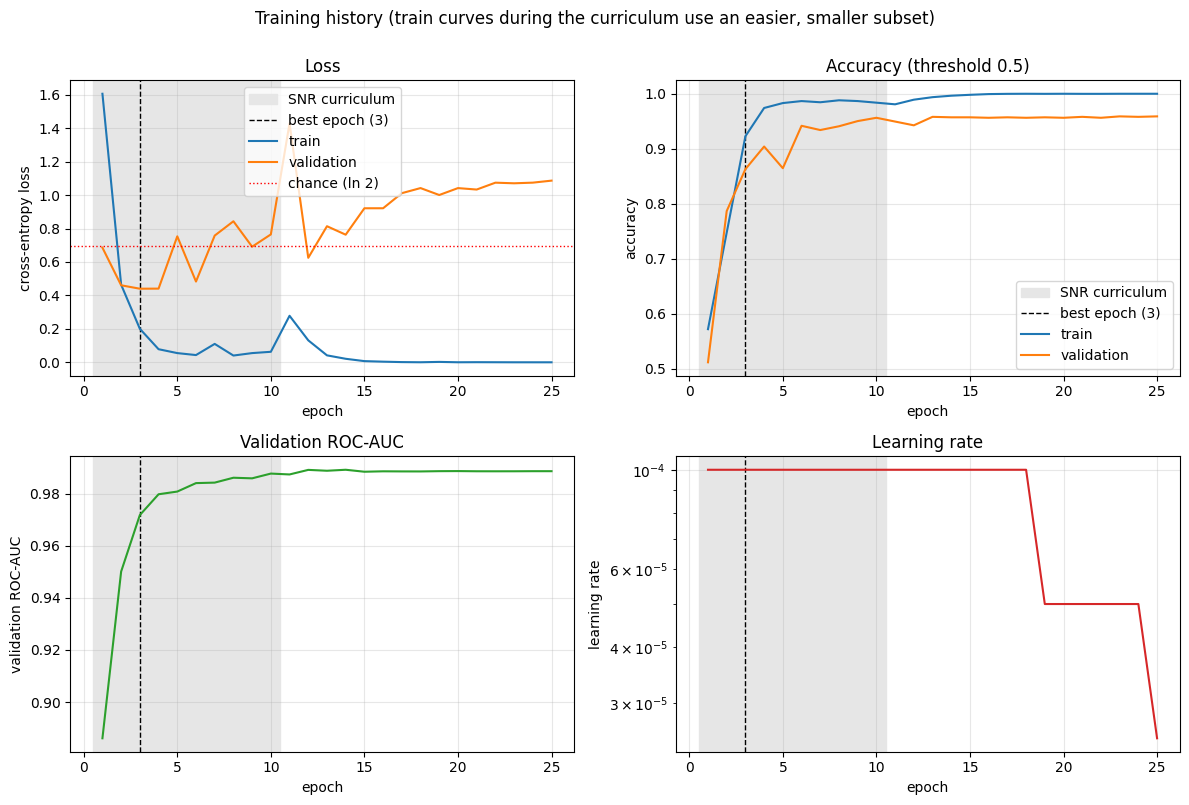

In [ ]:
def savefig(name):
    plt.savefig(OUTPUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


h = history_df
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax in axes.ravel():
    if CURRICULUM_EPOCHS > 0:
        ax.axvspan(0.5, min(CURRICULUM_EPOCHS, h["epoch"].max()) + 0.5, color="0.9", zorder=0,
                   label="SNR curriculum")
    ax.axvline(best_epoch, color="k", ls="--", lw=1, label=f"best epoch ({best_epoch})")
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)

ax = axes[0, 0]
ax.plot(h["epoch"], h["train_loss"], label="train")
ax.plot(h["epoch"], h["val_loss"], label="validation")
ax.axhline(np.log(2), color="r", ls=":", lw=1, label="chance (ln 2)")
ax.set_ylabel("cross-entropy loss"); ax.set_title("Loss"); ax.legend()

ax = axes[0, 1]
ax.plot(h["epoch"], h["train_acc"], label="train")
ax.plot(h["epoch"], h["val_acc"], label="validation")
ax.set_ylabel("accuracy"); ax.set_title("Accuracy (threshold 0.5)"); ax.legend()

ax = axes[1, 0]
ax.plot(h["epoch"], h["val_auc"], color="C2")
ax.set_ylabel("validation ROC-AUC"); ax.set_title("Validation ROC-AUC")

ax = axes[1, 1]
ax.semilogy(h["epoch"], h["lr"], color="C3")
ax.set_ylabel("learning rate"); ax.set_title("Learning rate")

fig.suptitle("Training history (train curves during the curriculum use an easier, smaller subset)", y=1.0)
fig.tight_layout()
savefig("01_training_curves")
plt.show()

## 9. Predictions and operating points

The model is evaluated on the **test set** for the first time here.

Two operating points are reported:

1. **Default** — `softmax P(signal) > 0.5` (`score > 0`).
2. **Fixed false-alarm probability** — the threshold is the `(1 − TARGET_FPR)` quantile of the **validation** noise-only scores, i.e. chosen without touching the test set. This is the operating point relevant for a detection pipeline (the paper tunes its classifier to < 1 % false alarms). The false-positive rate actually obtained on the test noise is reported alongside, with a 95 % Wilson interval.

In [ ]:
# ---- scores ---------------------------------------------------------------
val_logits = predict_logits(model, X_train, val_idx)
test_logits = predict_logits(model, X_test)

score_val, score_test = margin(val_logits), margin(test_logits)
prob_test = expit(score_test)                       # softmax probability of "signal"
y_val = y_train[val_idx]

assert np.isfinite(score_test).all() and np.isfinite(score_val).all()

# ---- operating points -----------------------------------------------------
noise_val_scores = score_val[y_val == 0]
if len(noise_val_scores) * TARGET_FPR < 5:
    print(f"WARNING: only {len(noise_val_scores)} validation noise examples; the threshold for "
          f"FPR={TARGET_FPR:.1%} is a very rough estimate.")
thr_far = float(np.quantile(noise_val_scores, 1.0 - TARGET_FPR))

OP_DEFAULT = "default (P>0.5)"
OP_FAR = f"fixed FPR={TARGET_FPR:.0%}"
operating_points = {OP_DEFAULT: 0.0, OP_FAR: thr_far}


def wilson_interval(k, n, z=1.96):
    """Wilson score interval for a binomial proportion (vectorised)."""
    k = np.asarray(k, dtype=float)
    n = np.asarray(n, dtype=float)
    with np.errstate(divide="ignore", invalid="ignore"):
        p = k / n
        denom = 1.0 + z ** 2 / n
        centre = (p + z ** 2 / (2.0 * n)) / denom
        half = z * np.sqrt(p * (1.0 - p) / n + z ** 2 / (4.0 * n ** 2)) / denom
    return np.clip(centre - half, 0.0, 1.0), np.clip(centre + half, 0.0, 1.0)


def operating_point_metrics(y, score, thr):
    pred = score > thr
    tp = int(np.sum((y == 1) & pred)); fn = int(np.sum((y == 1) & ~pred))
    fp = int(np.sum((y == 0) & pred)); tn = int(np.sum((y == 0) & ~pred))
    tpr = tp / (tp + fn); fpr = fp / (fp + tn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else float("nan")
    f1 = 2 * tp / (2 * tp + fp + fn)
    tpr_lo, tpr_hi = (float(v[()]) for v in wilson_interval(tp, tp + fn))
    fpr_lo, fpr_hi = (float(v[()]) for v in wilson_interval(fp, fp + tn))
    return dict(
        threshold=float(thr), tp=tp, fn=fn, fp=fp, tn=tn,
        accuracy=(tp + tn) / len(y), balanced_accuracy=0.5 * (tpr + 1 - fpr),
        recall_tpr=tpr, tpr_ci95=(tpr_lo, tpr_hi),
        fpr=fpr, fpr_ci95=(fpr_lo, fpr_hi),
        precision=precision, f1=f1, confusion=[[tn, fp], [fn, tp]],
    )


metrics_by_op = {name: operating_point_metrics(y_test, score_test, thr) for name, thr in operating_points.items()}

# ---- threshold-free metrics with bootstrap CIs ----------------------------
auc_test = float(roc_auc_score(y_test, score_test))
ap_test = float(average_precision_score(y_test, score_test))

boot_rng = np.random.default_rng(SEED + 2)
boot = {"auc": [], "ap": [], "acc_default": []}
for _ in range(N_BOOTSTRAP):
    i = boot_rng.integers(0, len(y_test), len(y_test))
    yy, ss = y_test[i], score_test[i]
    if yy.min() == yy.max():
        continue
    boot["auc"].append(roc_auc_score(yy, ss))
    boot["ap"].append(average_precision_score(yy, ss))
    boot["acc_default"].append(np.mean((ss > 0) == (yy == 1)))
ci = {k: tuple(float(v) for v in np.percentile(vals, [2.5, 97.5])) for k, vals in boot.items()}

test_loss = nll(test_logits, y_test)

print(f"Test cross-entropy loss : {test_loss:.4f}   (chance = {np.log(2):.4f})")
print(f"Test ROC-AUC            : {auc_test:.4f}   95% bootstrap CI [{ci['auc'][0]:.4f}, {ci['auc'][1]:.4f}]")
print(f"Test average precision  : {ap_test:.4f}   95% bootstrap CI [{ci['ap'][0]:.4f}, {ci['ap'][1]:.4f}]")
print(f"Test accuracy (P>0.5)   : {metrics_by_op[OP_DEFAULT]['accuracy']:.4f}   "
      f"95% bootstrap CI [{ci['acc_default'][0]:.4f}, {ci['acc_default'][1]:.4f}]")
print(f"\nThreshold for FPR={TARGET_FPR:.0%} chosen on validation noise: score > {thr_far:.3f}  "
      f"(P(signal) > {expit(thr_far):.4f})\n")

summary = pd.DataFrame({
    name: {
        "threshold (score)": m["threshold"],
        "accuracy": m["accuracy"],
        "balanced accuracy": m["balanced_accuracy"],
        "recall / TPR": m["recall_tpr"],
        "  TPR 95% CI": f"[{m['tpr_ci95'][0]:.3f}, {m['tpr_ci95'][1]:.3f}]",
        "FPR": m["fpr"],
        "  FPR 95% CI": f"[{m['fpr_ci95'][0]:.4f}, {m['fpr_ci95'][1]:.4f}]",
        "precision": m["precision"],
        "F1": m["f1"],
        "TP / FN / FP / TN": f"{m['tp']} / {m['fn']} / {m['fp']} / {m['tn']}",
    } for name, m in metrics_by_op.items()
})
display(summary)

Test cross-entropy loss : 0.8325   (chance = 0.6931)
Test ROC-AUC            : 0.9682   95% bootstrap CI [0.9602, 0.9753]
Test average precision  : 0.9761   95% bootstrap CI [0.9700, 0.9807]
Test accuracy (P>0.5)   : 0.8425   95% bootstrap CI [0.8265, 0.8585]

Threshold for FPR=1% chosen on validation noise: score > -1.027  (P(signal) > 0.2636)



,default (P>0.5),fixed FPR=1%
threshold (score),0.0,-1.027221
accuracy,0.8425,0.8875
balanced accuracy,0.8425,0.8875
recall / TPR,0.686,0.784
TPR 95% CI,"[0.657, 0.714]","[0.757, 0.808]"
FPR,0.001,0.009
FPR 95% CI,"[0.0002, 0.0056]","[0.0047, 0.0170]"
precision,0.998544,0.988651
F1,0.813278,0.874512
TP / FN / FP / TN,686 / 314 / 1 / 999,784 / 216 / 9 / 991


## 10. Confusion matrices

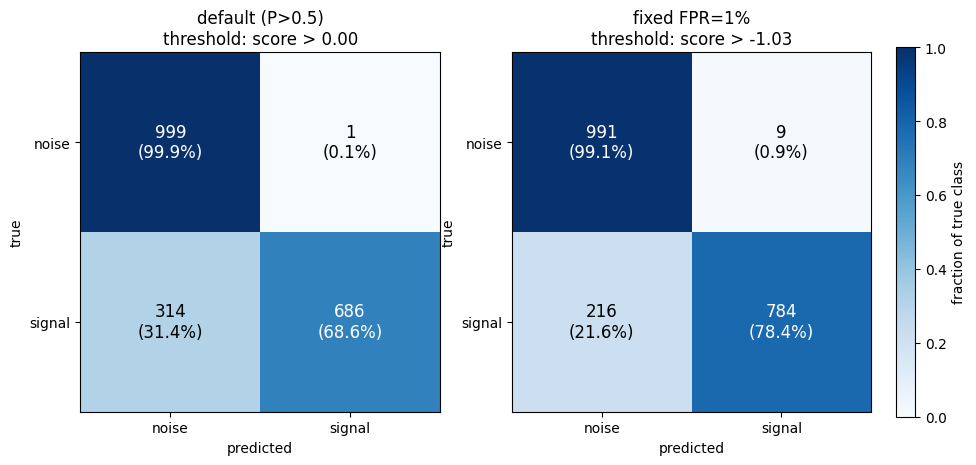

In [ ]:
fig, axes = plt.subplots(1, len(operating_points), figsize=(5.4 * len(operating_points), 4.8))
axes = np.atleast_1d(axes)

for ax, (name, m) in zip(axes, metrics_by_op.items()):
    cm = np.array(m["confusion"])
    cmn = cm / cm.sum(axis=1, keepdims=True)
    im = ax.imshow(cmn, vmin=0, vmax=1, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n({cmn[i, j]:.1%})", ha="center", va="center",
                    color="white" if cmn[i, j] > 0.5 else "black", fontsize=12)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["noise", "signal"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["noise", "signal"])
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.set_title(f"{name}\nthreshold: score > {m['threshold']:.2f}")

fig.colorbar(im, ax=axes.tolist(), fraction=0.025, pad=0.03, label="fraction of true class")
savefig("02_confusion_matrices")
plt.show()

## 11. ROC and precision-recall curves

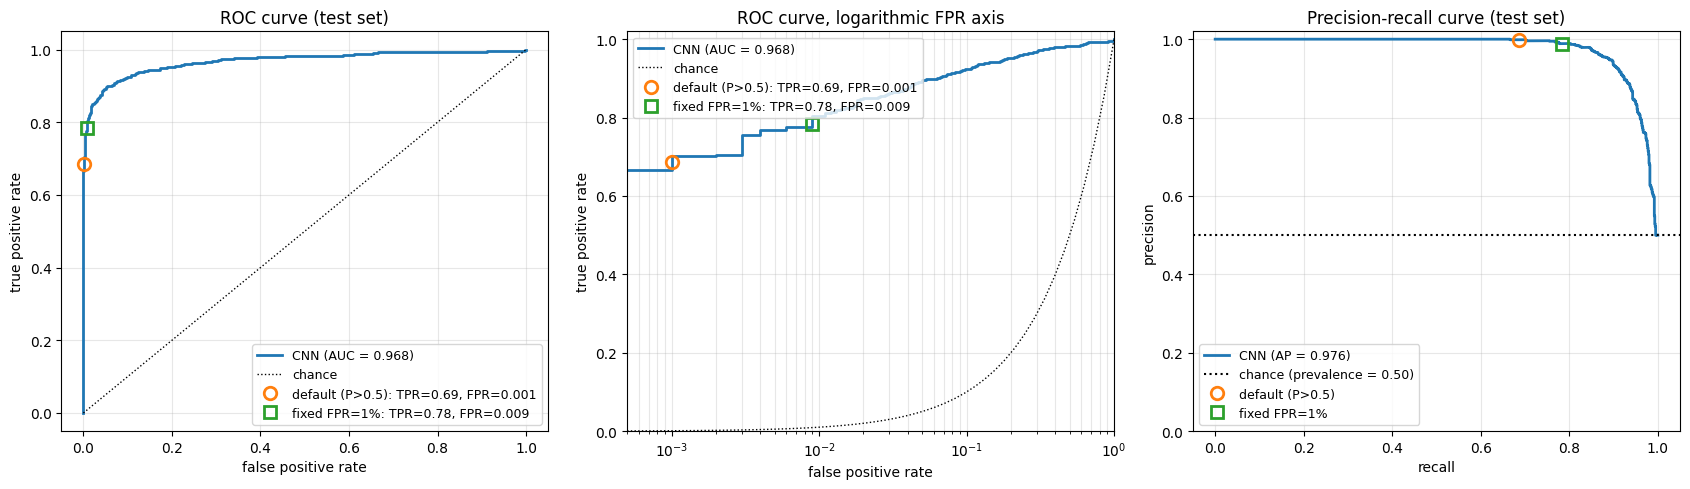

In [ ]:
fpr_c, tpr_c, _ = roc_curve(y_test, score_test)
prec_c, rec_c, _ = precision_recall_curve(y_test, score_test)
n_neg = int(np.sum(y_test == 0))
prevalence = float(np.mean(y_test == 1))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for k, ax in enumerate(axes[:2]):
    ax.plot(fpr_c, tpr_c, lw=2, label=f"CNN (AUC = {auc_test:.3f})")
    if k == 0:
        ax.plot([0, 1], [0, 1], "k:", lw=1, label="chance")
    else:
        xc = np.logspace(np.log10(0.5 / n_neg), 0, 50)
        ax.plot(xc, xc, "k:", lw=1, label="chance")
    for (name, m), marker in zip(metrics_by_op.items(), ("o", "s")):
        ax.plot(max(m["fpr"], 0.5 / n_neg) if k == 1 else m["fpr"], m["recall_tpr"], marker,
                ms=9, mfc="none", mew=2, label=f"{name}: TPR={m['recall_tpr']:.2f}, FPR={m['fpr']:.3f}")
    ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
    ax.grid(alpha=0.3, which="both")
    if k == 0:
        ax.set_title("ROC curve (test set)")
    else:
        ax.set_xscale("log"); ax.set_xlim(0.5 / n_neg, 1.0); ax.set_ylim(0, 1.02)
        ax.set_title("ROC curve, logarithmic FPR axis")
    ax.legend(loc="lower right" if k == 0 else "upper left", fontsize=9)

ax = axes[2]
ax.plot(rec_c, prec_c, lw=2, label=f"CNN (AP = {ap_test:.3f})")
ax.axhline(prevalence, color="k", ls=":", label=f"chance (prevalence = {prevalence:.2f})")
for (name, m), marker in zip(metrics_by_op.items(), ("o", "s")):
    if np.isfinite(m["precision"]):
        ax.plot(m["recall_tpr"], m["precision"], marker, ms=9, mfc="none", mew=2, label=name)
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_ylim(0, 1.02)
ax.set_title("Precision-recall curve (test set)"); ax.grid(alpha=0.3); ax.legend(loc="lower left", fontsize=9)

fig.tight_layout()
savefig("03_roc_pr")
plt.show()

## 12. Score distributions and calibration

Left: distribution of the detection statistic (logit margin) for noise and for signals. Right: reliability diagram — if the network's probabilities were perfectly calibrated the points would lie on the diagonal. (The training set is balanced 50/50, so the probabilities are calibrated for that prior only, not for the real, very low, signal rate.)

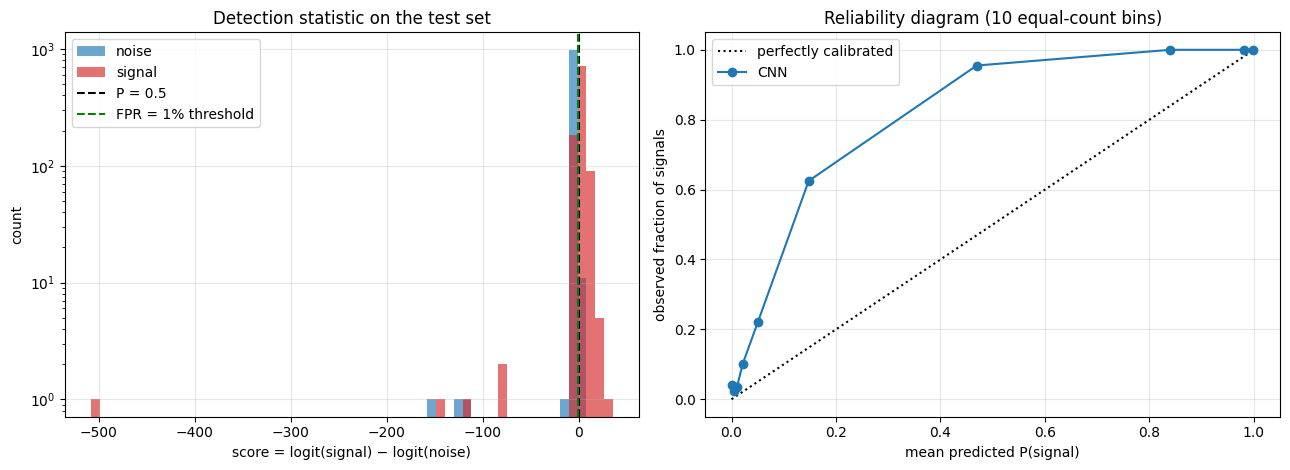

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

ax = axes[0]
bins = np.linspace(score_test.min(), score_test.max(), 60)
ax.hist(score_test[y_test == 0], bins=bins, alpha=0.65, label="noise", color="C0")
ax.hist(score_test[y_test == 1], bins=bins, alpha=0.65, label="signal", color="C3")
ax.set_yscale("log")
ax.axvline(0.0, color="k", ls="--", label="P = 0.5")
ax.axvline(thr_far, color="g", ls="--", label=f"FPR = {TARGET_FPR:.0%} threshold")
ax.set_xlabel("score = logit(signal) − logit(noise)"); ax.set_ylabel("count")
ax.set_title("Detection statistic on the test set"); ax.legend(); ax.grid(alpha=0.3)

ax = axes[1]
frac_pos, mean_pred = calibration_curve(y_test, prob_test, n_bins=10, strategy="quantile")
ax.plot([0, 1], [0, 1], "k:", label="perfectly calibrated")
ax.plot(mean_pred, frac_pos, "o-", label="CNN")
ax.set_xlabel("mean predicted P(signal)"); ax.set_ylabel("observed fraction of signals")
ax.set_title("Reliability diagram (10 equal-count bins)"); ax.legend(); ax.grid(alpha=0.3)

fig.tight_layout()
savefig("04_scores_calibration")
plt.show()

## 13. Detection efficiency vs. injected SNR

This is the central figure of the paper (its Fig. 4): the fraction of injected signals that are detected, as a function of the optimal matched-filter SNR, shown for both operating points. Bins hold equal numbers of signals; error bars are 95 % Wilson intervals. The SNR is read from the test metadata (`snr_H1` is the SNR in the reference detector that the dataset draws uniformly in 4-10; `snr_network` combines H1 and L1).

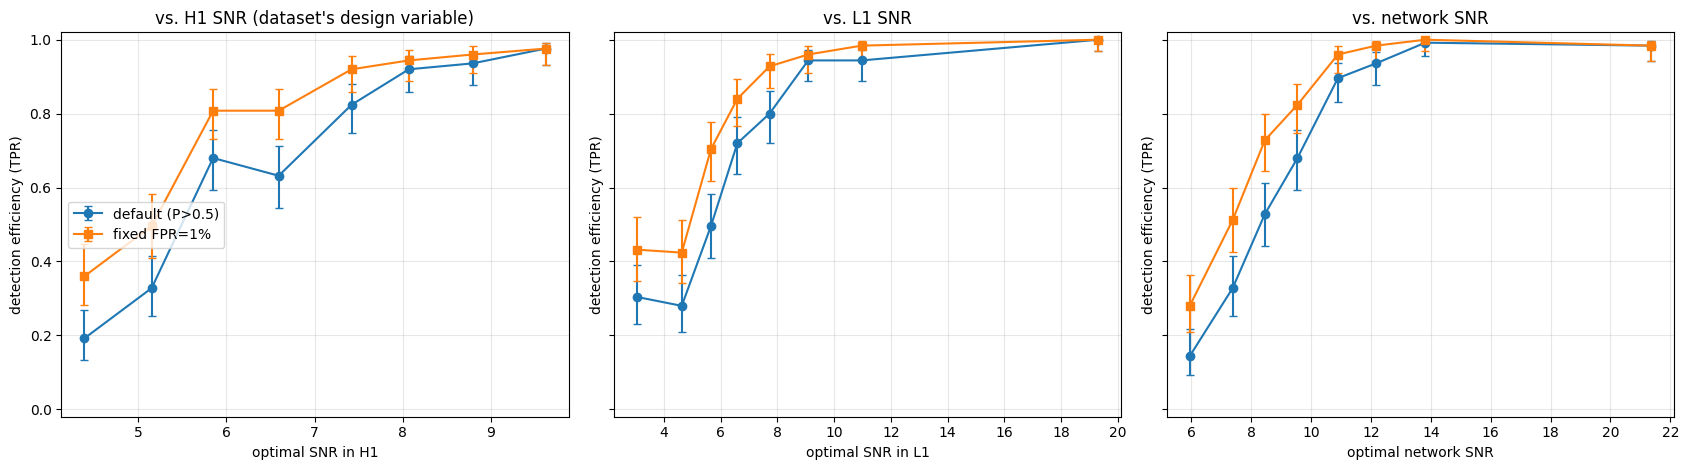

,H1 SNR bin,n signals,ROC-AUC (bin vs. all noise),TPR @ default,TPR @ fixed FPR=1%
0,"(4.00, 5.54]",250,0.9130,0.260,0.428
1,"(5.54, 7.05]",250,0.9834,0.656,0.808
2,"(7.05, 8.40]",250,0.9935,0.872,0.932
3,"(8.40, 10.00]",250,0.9830,0.956,0.968


In [ ]:
def efficiency_table(values, detected, n_bins):
    """Detection fraction (with Wilson 95 % CI) in equal-count bins of `values`."""
    df = pd.DataFrame({"x": np.asarray(values, dtype=float), "det": np.asarray(detected).astype(int)})
    df["bin"] = pd.qcut(df["x"], q=n_bins, duplicates="drop")
    tab = (df.groupby("bin", observed=True)
             .agg(x=("x", "mean"), k=("det", "sum"), n=("det", "size"))
             .reset_index(drop=True))
    tab["eff"] = tab["k"] / tab["n"]
    tab["lo"], tab["hi"] = wilson_interval(tab["k"], tab["n"])
    return tab


def plot_efficiency(ax, values, scores, xlabel, n_bins):
    for (name, thr), marker in zip(operating_points.items(), ("o", "s")):
        tab = efficiency_table(values, scores > thr, n_bins)
        eff = tab["eff"].to_numpy()
        yerr = np.vstack([np.clip(eff - tab["lo"].to_numpy(), 0, None),
                          np.clip(tab["hi"].to_numpy() - eff, 0, None)])
        ax.errorbar(tab["x"], eff, yerr=yerr, marker=marker, capsize=3, label=name)
    ax.set_xlabel(xlabel); ax.set_ylabel("detection efficiency (TPR)")
    ax.set_ylim(-0.02, 1.02); ax.grid(alpha=0.3)


sig = np.flatnonzero(y_test == 1)
snr_h1_sig = meta_test["snr_H1"].to_numpy(dtype=float)[sig]
snr_l1_sig = meta_test["snr_L1"].to_numpy(dtype=float)[sig]
snr_net_sig = meta_test["snr_network"].to_numpy(dtype=float)[sig]
score_sig = score_test[sig]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
plot_efficiency(axes[0], snr_h1_sig, score_sig, "optimal SNR in H1", 8)
plot_efficiency(axes[1], snr_l1_sig, score_sig, "optimal SNR in L1", 8)
plot_efficiency(axes[2], snr_net_sig, score_sig, "optimal network SNR", 8)
axes[0].set_title("vs. H1 SNR (dataset's design variable)")
axes[1].set_title("vs. L1 SNR")
axes[2].set_title("vs. network SNR")
axes[0].legend(loc="center left")
fig.tight_layout()
savefig("05_efficiency_vs_snr")
plt.show()

# ---- table: per H1-SNR bin -------------------------------------------------
noise_scores_test = score_test[y_test == 0]
snr_bins = pd.qcut(pd.Series(snr_h1_sig), q=4, duplicates="drop")
rows = []
for interval in snr_bins.cat.categories:
    sel = (snr_bins == interval).to_numpy()
    s = score_sig[sel]
    auc_bin = roc_auc_score(np.r_[np.zeros(len(noise_scores_test)), np.ones(len(s))],
                            np.r_[noise_scores_test, s])
    rows.append({
        "H1 SNR bin": f"({interval.left:.2f}, {interval.right:.2f}]",
        "n signals": int(sel.sum()),
        "ROC-AUC (bin vs. all noise)": round(float(auc_bin), 4),
        f"TPR @ default": round(float(np.mean(s > 0)), 4),
        f"TPR @ {OP_FAR}": round(float(np.mean(s > thr_far)), 4),
    })
snr_table = pd.DataFrame(rows)
display(snr_table)

## 14. Detection efficiency vs. mass

Because the SNR is fixed by construction, any remaining dependence on mass shows where the network is intrinsically better or worse (very heavy systems merge inside the band with only a few cycles, light systems have long inspirals).

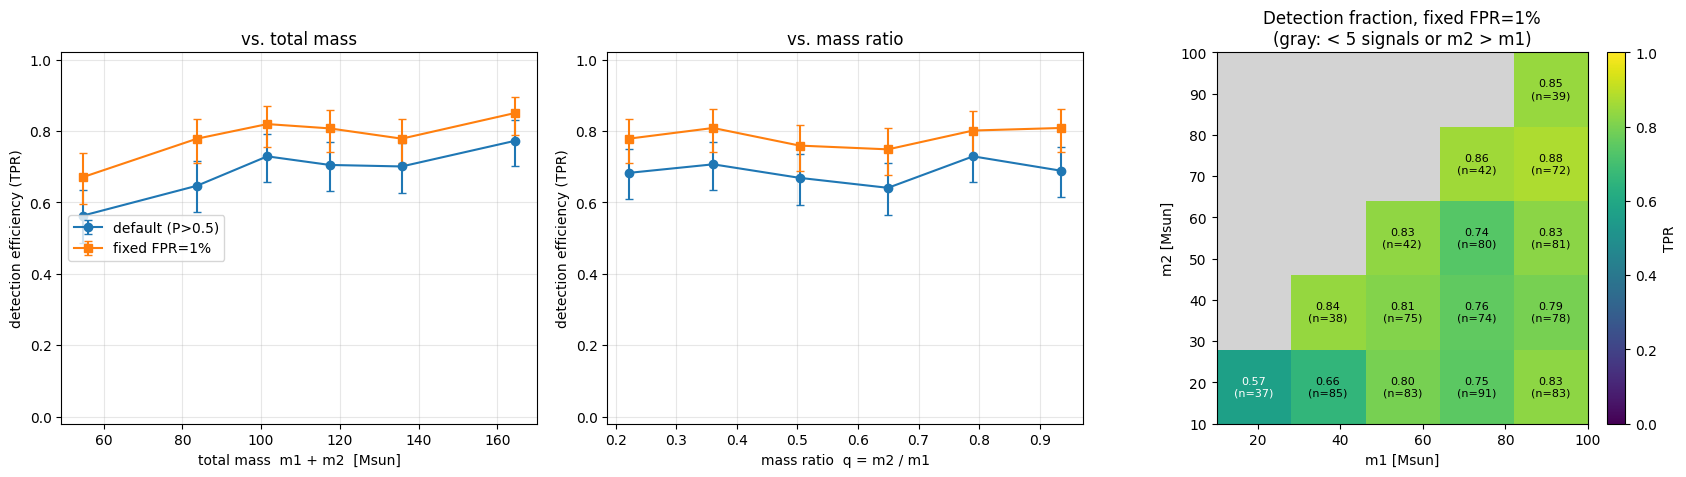

In [ ]:
m1 = meta_test["mass1"].to_numpy(dtype=float)[sig]
m2 = meta_test["mass2"].to_numpy(dtype=float)[sig]
det_far = score_sig > thr_far

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# efficiency vs total mass
plot_efficiency(axes[0], m1 + m2, score_sig, "total mass  m1 + m2  [Msun]", 6)
axes[0].set_title("vs. total mass"); axes[0].legend(loc="center left")

# efficiency vs mass ratio q = m2/m1 <= 1
plot_efficiency(axes[1], m2 / m1, score_sig, "mass ratio  q = m2 / m1", 6)
axes[1].set_title("vs. mass ratio")

# detection fraction in the (m1, m2) plane at the fixed-FPR threshold
MIN_PER_CELL = 5
edges = np.linspace(10.0, 100.0, 6)
n_all, _, _ = np.histogram2d(m1, m2, bins=[edges, edges])
n_det, _, _ = np.histogram2d(m1[det_far], m2[det_far], bins=[edges, edges])
frac = np.where(n_all >= MIN_PER_CELL, n_det / np.maximum(n_all, 1), np.nan)

cmap = plt.get_cmap("viridis").copy()
cmap.set_bad("lightgray")
ax = axes[2]
im = ax.imshow(np.ma.masked_invalid(frac.T), origin="lower", extent=[10, 100, 10, 100],
               vmin=0, vmax=1, cmap=cmap, aspect="equal")
centres = 0.5 * (edges[:-1] + edges[1:])
for i, cx in enumerate(centres):
    for j, cy in enumerate(centres):
        if n_all[i, j] >= MIN_PER_CELL:
            ax.text(cx, cy, f"{frac[i, j]:.2f}\n(n={int(n_all[i, j])})", ha="center", va="center",
                    fontsize=8, color="white" if frac[i, j] < 0.6 else "black")
ax.set_xlabel("m1 [Msun]"); ax.set_ylabel("m2 [Msun]")
ax.set_title(f"Detection fraction, {OP_FAR}\n(gray: < {MIN_PER_CELL} signals or m2 > m1)")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="TPR")

fig.tight_layout()
savefig("06_efficiency_vs_mass")
plt.show()

## 15. Mistakes: false alarms and loudest missed signals

At the default threshold: the two noise windows that received the highest scores, and the two *missed* signals with the highest network SNR (the ones a good detector should have found). Whitened strain, H1 and L1.

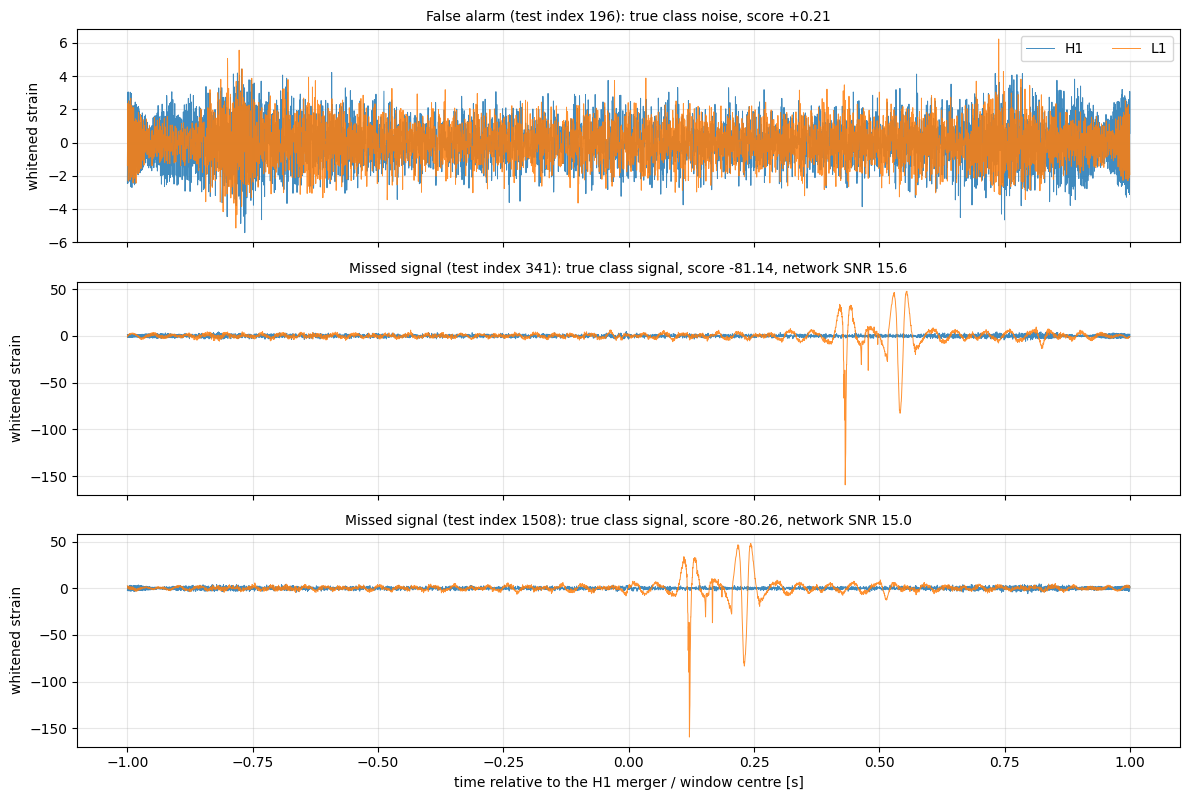

In [ ]:
pred_default = score_test > 0
snr_net_test = meta_test["snr_network"].to_numpy(dtype=float)

fp_idx = np.flatnonzero((y_test == 0) & pred_default)
fp_idx = fp_idx[np.argsort(-score_test[fp_idx])][:2]
missed = np.flatnonzero((y_test == 1) & ~pred_default)
fn_idx = missed[np.argsort(-snr_net_test[missed])][:2]

cases = [("False alarm", int(i)) for i in fp_idx] + [("Missed signal", int(i)) for i in fn_idx]

if not cases:
    print("No false alarms and no missed signals at the default threshold.")
else:
    t = (np.arange(N_SAMPLES) - N_SAMPLES // 2) / FS
    fig, axes = plt.subplots(len(cases), 1, figsize=(12, 2.7 * len(cases)), sharex=True)
    axes = np.atleast_1d(axes)
    for ax, (kind, i) in zip(axes, cases):
        ax.plot(t, X_test[i, 0], lw=0.7, label="H1", alpha=0.85)
        ax.plot(t, X_test[i, 1], lw=0.7, label="L1", alpha=0.85)
        ax.set_ylabel("whitened strain")
        snr_txt = f", network SNR {snr_net_test[i]:.1f}" if y_test[i] == 1 else ""
        ax.set_title(f"{kind} (test index {i}): true class {'signal' if y_test[i] else 'noise'}, "
                     f"score {score_test[i]:+.2f}{snr_txt}", fontsize=10)
        ax.grid(alpha=0.3)
    axes[0].legend(loc="upper right", ncol=2)
    axes[-1].set_xlabel("time relative to the H1 merger / window centre [s]")
    fig.tight_layout()
    savefig("07_misclassified_examples")
    plt.show()

## 16. Save the results and final summary

In [ ]:
def to_py(o):
    if isinstance(o, dict):
        return {k: to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_py(v) for v in o]
    if isinstance(o, (np.floating, float)):
        return float(o)
    if isinstance(o, (np.integer, int)):
        return int(o)
    return o


results = dict(
    test_loss=test_loss,
    test_roc_auc=auc_test, test_roc_auc_ci95=ci["auc"],
    test_average_precision=ap_test, test_average_precision_ci95=ci["ap"],
    test_accuracy_default_ci95=ci["acc_default"],
    target_fpr=TARGET_FPR, threshold_fpr_from_validation=thr_far,
    operating_points=metrics_by_op,
    snr_table=snr_table.to_dict(orient="records"),
    best_epoch=int(best_epoch), n_train=int(len(train_idx)), n_val=int(len(val_idx)), n_test=int(len(y_test)),
)
with open(OUTPUT_DIR / "test_metrics.json", "w") as f:
    json.dump(to_py(results), f, indent=2)

pred_df = meta_test.copy()
pred_df["y_true"] = y_test
pred_df["score"] = score_test
pred_df["prob_signal"] = prob_test
pred_df["pred_default"] = (score_test > 0).astype(int)
pred_df["pred_fixed_fpr"] = (score_test > thr_far).astype(int)
pred_df.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

m0, m1_ = metrics_by_op[OP_DEFAULT], metrics_by_op[OP_FAR]
print("=" * 72)
print("FINAL TEST-SET SUMMARY  (best epoch %d, %d train / %d val / %d test examples)"
      % (best_epoch, len(train_idx), len(val_idx), len(y_test)))
print("=" * 72)
print(f"ROC-AUC                      : {auc_test:.4f}  [{ci['auc'][0]:.4f}, {ci['auc'][1]:.4f}]")
print(f"Average precision            : {ap_test:.4f}  [{ci['ap'][0]:.4f}, {ci['ap'][1]:.4f}]")
print(f"Accuracy  (P > 0.5)          : {m0['accuracy']:.4f}  [{ci['acc_default'][0]:.4f}, {ci['acc_default'][1]:.4f}]")
print(f"  TPR / FPR                  : {m0['recall_tpr']:.4f} / {m0['fpr']:.4f}")
print(f"At FPR target {TARGET_FPR:.0%} (threshold from validation):")
print(f"  test FPR                   : {m1_['fpr']:.4f}  [{m1_['fpr_ci95'][0]:.4f}, {m1_['fpr_ci95'][1]:.4f}]")
print(f"  detection efficiency (TPR) : {m1_['recall_tpr']:.4f}  [{m1_['tpr_ci95'][0]:.4f}, {m1_['tpr_ci95'][1]:.4f}]")
print("=" * 72)
print("Files written to", OUTPUT_DIR.resolve())
for p in sorted(OUTPUT_DIR.iterdir()):
    print("  ", p.name)

FINAL TEST-SET SUMMARY  (best epoch 3, 6777 train / 1168 val / 2000 test examples)
ROC-AUC                      : 0.9682  [0.9602, 0.9753]
Average precision            : 0.9761  [0.9700, 0.9807]
Accuracy  (P > 0.5)          : 0.8425  [0.8265, 0.8585]
  TPR / FPR                  : 0.6860 / 0.0010
At FPR target 1% (threshold from validation):
  test FPR                   : 0.0090  [0.0047, 0.0170]
  detection efficiency (TPR) : 0.7840  [0.7574, 0.8084]
Files written to /content/gw_cnn_outputs
   01_training_curves.png
   02_confusion_matrices.png
   03_roc_pr.png
   04_scores_calibration.png
   05_efficiency_vs_snr.png
   06_efficiency_vs_mass.png
   07_misclassified_examples.png
   config.json
   deep_filtering_cnn_best.pt
   test_metrics.json
   test_predictions.csv
   training_history.csv


## 17. How to read the results (and limitations)

* **SNR is the main driver.** Signals have an optimal H1 SNR of 4-10 by construction, so the lowest-SNR signals are intrinsically close to undetectable at a 1 % false-alarm level; judge the network by the *efficiency-vs-SNR* curve, not only by overall accuracy. The paper reports ~100 % sensitivity above SNR ≈ 10 in its setup (different noise, single detector, simulated templates restricted to 5-75 Msun, optimal orientation, 1 s windows), so the numbers here are not directly comparable.
* **Threshold choice matters.** Accuracy at `P > 0.5` assumes equal priors; a real search needs a low false-alarm rate, which is why the fixed-FPR operating point is reported. The test FPR with its confidence interval tells you how well the validation-chosen threshold transfers.
* **The merger is always at the window centre** in this dataset (training and test). The paper randomly shifted the peak within the last 0.2 s for robustness to time translation; for a sliding-window search on continuous data, augment with time shifts (re-generate the data with shifted injections — a circular shift of the stored windows would wrap the Tukey taper and is not equivalent).
* **Noise windows are random crops** of the GWOSC files without data-quality vetoes, so real glitches (and possibly real events) can occur in both classes. Glitches in the test noise lower the specificity — this is intended to resemble real data, as in the paper.
* **Generalisation to other epochs / PSDs** is only tested if you add file pairs from other times to the dataset notebook's `raw_noise/` folder; the paper's cross-event test used different GW events for training and testing.
* **Tuning, if needed**: loss stuck near 0.693 → raise `LEARNING_RATE` or `CURRICULUM_EPOCHS`; strong over-fitting (train accuracy ≫ validation accuracy, best epoch very early) → generate a larger training set in the dataset notebook (`N_TRAIN`), which is by far the most effective remedy; a single run's metrics also depend on the random seed, so compare changes over several `SEED` values.